<a href="https://colab.research.google.com/github/SrEffry/Mamografias/blob/main/02_eda_particion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

# Ajustado automáticamente para incluir la subcarpeta correcta encontrada en tu Drive
DATA = "/content/drive/MyDrive/Aprendizaje final/Csv"

def cargar(archivo, particion):
    df = pd.read_csv(f"{DATA}/{archivo}")
    df = df.rename(columns={"breast density": "breast_density"})
    for c in ["image file path", "cropped image file path", "ROI mask file path"]:
        df[c] = df[c].str.strip()          # las rutas traen saltos de línea al final
    df["label"] = (df["pathology"] == "MALIGNANT").astype(int)
    df["lesion_id"] = (df["patient_id"] + "_" + df["left or right breast"] + "_"
                       + df["image view"] + "_" + df["abnormality id"].astype(str))
    df["carpeta_roi"] = df["cropped image file path"].str.split("/").str[0]
    df["particion_oficial"] = particion
    return df

tr = cargar("mass_case_description_train_set.csv", "train")
te = cargar("mass_case_description_test_set.csv", "test")
df = pd.concat([tr, te], ignore_index=True)

print("Filas:", len(df), "| lesion_id único:", df.lesion_id.is_unique,
      "| filas duplicadas:", df.duplicated().sum())

Filas: 1696 | lesion_id único: True | filas duplicadas: 0


In [19]:
import os

base_path = "/content/drive/MyDrive/Aprendizaje final"
print(f"Buscando archivos CSV en {base_path}...")

if os.path.exists(base_path):
    csv_files = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.endswith('.csv'):
                full_path = os.path.join(root, file)
                csv_files.append(full_path)
                print(f"Encontrado: {full_path}")

    if not csv_files:
        print("No se encontró ningún archivo .csv en esta ruta de Drive.")
else:
    print(f"La ruta base '{base_path}' no existe. Contenido de '/content/drive/MyDrive':")
    try:
        print(os.listdir("/content/drive/MyDrive"))
    except Exception as e:
        print("Error al listar Drive:", e)

Buscando archivos CSV en /content/drive/MyDrive/Aprendizaje final...
Encontrado: /content/drive/MyDrive/Aprendizaje final/Images/indice_dicom.csv
Encontrado: /content/drive/MyDrive/Aprendizaje final/Csv/mass_case_description_train_set.csv
Encontrado: /content/drive/MyDrive/Aprendizaje final/Csv/mass_case_description_test_set.csv


In [25]:
print(pd.crosstab(df.particion_oficial, df.pathology, margins=True))
print(pd.crosstab(df.particion_oficial, df.label, normalize="index").round(3))

pathology          BENIGN  BENIGN_WITHOUT_CALLBACK  MALIGNANT   All
particion_oficial                                                  
test                  194                       37        147   378
train                 577                      104        637  1318
All                   771                      141        784  1696
label                  0      1
particion_oficial              
test               0.611  0.389
train              0.517  0.483


In [26]:
lpp = df.groupby("patient_id").size()
print("Pacientes:", df.patient_id.nunique())
print("Lesiones por paciente:", lpp.value_counts().sort_index().to_dict())
print("Imágenes completas distintas:", df["image file path"].nunique(), "de", len(df), "lesiones")

Pacientes: 892
Lesiones por paciente: {1: 251, 2: 578, 3: 16, 4: 25, 5: 7, 6: 12, 8: 1, 12: 1, 14: 1}
Imágenes completas distintas: 1592 de 1696 lesiones


In [27]:
print(pd.crosstab(df.particion_oficial, df["image view"]))
print(pd.crosstab(df.particion_oficial, df["left or right breast"]))
print(pd.crosstab(df.particion_oficial, df.breast_density))
print(df.groupby("breast_density").label.mean().round(3).to_dict())

image view          CC  MLO
particion_oficial          
test               177  201
train              607  711
left or right breast  LEFT  RIGHT
particion_oficial                
test                   186    192
train                  631    687
breast_density       1    2    3    4
particion_oficial                    
test                50  172  112   44
train              287  585  337  109
{1: 0.472, 2: 0.473, 3: 0.457, 4: 0.405}


In [28]:
print(df.isna().sum()[df.isna().sum() > 0])
print(pd.crosstab(df.assessment, df.label))
print(pd.crosstab(df.subtlety, df.label))

mass shape       4
mass margins    60
dtype: int64
label         0    1
assessment          
0           140   22
1             0    3
2            90    1
3           315   49
4           356  346
5            11  363
label       0    1
subtlety          
0           2    0
1          21   34
2          64   77
3         229  129
4         276  177
5         320  367


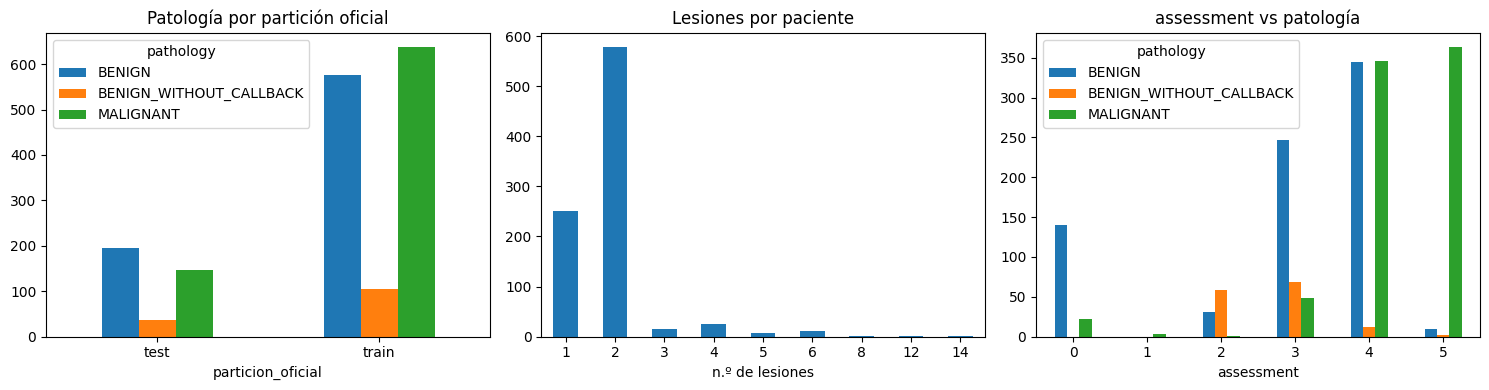

['eda_tabular.png']


In [29]:
import os

# Carpeta de resultados dentro de tu Drive (usando tu variable DATA)
RESULTADOS = f"{DATA}/resultados"
os.makedirs(RESULTADOS, exist_ok=True)

# Lesiones por paciente
lpp = df.groupby("patient_id").size()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

pd.crosstab(df.particion_oficial, df.pathology).plot.bar(ax=ax[0], rot=0)
ax[0].set_title("Patología por partición oficial")

lpp.value_counts().sort_index().plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Lesiones por paciente")
ax[1].set_xlabel("n.º de lesiones")

pd.crosstab(df.assessment, df.pathology).plot.bar(ax=ax[2], rot=0)
ax[2].set_title("assessment vs patología")

plt.tight_layout()
plt.savefig(f"{RESULTADOS}/eda_tabular.png", dpi=120, bbox_inches="tight")
plt.show()

# Comprobación: debe aparecer eda_tabular.png
print(os.listdir(RESULTADOS))

In [30]:
import os
import pandas as pd

ROOT = "/content/drive/MyDrive/Aprendizaje final/Images"
cbis_path = os.path.join(ROOT, "cbis_ddsm")

# 1. Obtener la lista de nombres de archivos reales descargados (.dcm)
archivos_en_drive = {f for f in os.listdir(cbis_path) if f.endswith(".dcm")}

# 2. Leer todos los manifiestos para mapear qué (Patient ID, Study ID, Series ID) tenemos descargados
series_descargadas = set()

manifests = [f for f in os.listdir(ROOT) if f.startswith("idc_file_id_manifest") and f.endswith(".txt")]
for manifest in manifests:
    path_manifest = os.path.join(ROOT, manifest)
    try:
        # Leemos el manifiesto como un DataFrame de pandas
        m_df = pd.read_csv(path_manifest)
        # Filtrar solo por aquellos archivos que realmente existen en el Drive
        m_df_existentes = m_df[m_df["File Instance Name"].isin(archivos_en_drive)]

        # Agregamos los identificadores únicos a nuestro conjunto
        for _, row in m_df_existentes.iterrows():
            # Guardamos la combinación (Series ID o Study ID) que nos permita identificarlo
            series_descargadas.add(str(row["Series ID"]).strip())
    except Exception as e:
        print(f"Error al leer el manifiesto {manifest}: {e}")

# 3. Marcar las filas del DataFrame original si su Series ID está en la lista de descargadas
# Extraemos el Series ID desde la ruta de la imagen en tu DataFrame (suele ser el penúltimo elemento de la ruta)
def extraer_series_id(ruta):
    if pd.isna(ruta):
        return None
    partes = ruta.split("/")
    if len(partes) >= 2:
        return partes[-2] # El directorio inmediatamente anterior al .dcm suele ser el Series ID
    return None

df["series_id_completo"] = df["image file path"].apply(extraer_series_id)
df["series_id_cropped"] = df["cropped image file path"].apply(extraer_series_id)
df["series_id_roi"] = df["ROI mask file path"].apply(extraer_series_id)

# Marcamos como "tiene_imagen" si cualquiera de sus Series ID correspondientes fue descargada
df["tiene_imagen"] = (
    df["series_id_completo"].isin(series_descargadas) |
    df["series_id_cropped"].isin(series_descargadas) |
    df["series_id_roi"].isin(series_descargadas)
)

# Mostrar el resultado final corregido
print("Imágenes descargadas por partición:")
print(df.groupby("particion_oficial").tiene_imagen.agg(["sum", "count"]))

# Guardamos las lesiones descargadas
with open("lesiones_descargadas.txt", "w") as f:
    f.write("\n".join(df.loc[df.tiene_imagen, "lesion_id"]))
print(f"\nArchivo 'lesiones_descargadas.txt' generado con éxito con {df.tiene_imagen.sum()} registros.")

Imágenes descargadas por partición:
                   sum  count
particion_oficial            
test                 0    378
train               59   1318

Archivo 'lesiones_descargadas.txt' generado con éxito con 59 registros.


In [31]:
import os
import pandas as pd

# Definir rutas nuevamente para asegurar consistencia
ROOT = "/content/drive/MyDrive/Aprendizaje final/Images"
cbis_path = os.path.join(ROOT, "cbis_ddsm")

# 1. Listar TODOS los archivos .dcm reales en la carpeta
archivos_reales = [f for f in os.listdir(cbis_path) if f.endswith(".dcm")]
print(f"[Diagnóstico] Total de archivos .dcm reales en disco: {len(archivos_reales)}")

# 2. Consolidar la información de todos los manifiestos
manifests = [f for f in os.listdir(ROOT) if f.startswith("idc_file_id_manifest") and f.endswith(".txt")]

all_manifest_rows = []
for manifest in manifests:
    path_manifest = os.path.join(ROOT, manifest)
    try:
        m_df = pd.read_csv(path_manifest)
        all_manifest_rows.append(m_df)
    except Exception as e:
        print(f"Error leyendo manifest {manifest}: {e}")

if all_manifest_rows:
    df_manifests = pd.concat(all_manifest_rows, ignore_index=True).drop_duplicates()
    print(f"[Diagnóstico] Total de registros únicos en todos los manifiestos consolidados: {len(df_manifests)}")

    # Filtrar el manifiesto por los archivos que realmente existen en disco
    df_manifests_existentes = df_manifests[df_manifests["File Instance Name"].isin(archivos_reales)]
    archivos_encontrados_en_manifest = df_manifests_existentes["File Instance Name"].nunique()
    print(f"[Diagnóstico] De los {len(archivos_reales)} archivos en disco, cuántos tienen registro en los manifiestos: {archivos_encontrados_en_manifest}")

    # Ver cuáles archivos NO se encontraron en los manifiestos
    no_encontrados = set(archivos_reales) - set(df_manifests_existentes["File Instance Name"])
    if no_encontrados:
        print(f"[Alerta] Hay {len(no_encontrados)} archivos en disco que NO aparecen en ningún manifiesto. Ejemplo:")
        print(list(no_encontrados)[:5])

    # 3. Analizar la coincidencia con el DataFrame original (Series ID)
    series_en_disco = set(df_manifests_existentes["Series ID"].astype(str).str.strip())

    # Extraer los Series ID del DataFrame de metadatos original
    df_metadata = df.copy()
    df_metadata["series_id_completo"] = df_metadata["image file path"].apply(extraer_series_id)
    df_metadata["series_id_cropped"] = df_metadata["cropped image file path"].apply(extraer_series_id)
    df_metadata["series_id_roi"] = df_metadata["ROI mask file path"].apply(extraer_series_id)

    series_metadata = set()
    for col in ["series_id_completo", "series_id_cropped", "series_id_roi"]:
        series_metadata.update(df_metadata[col].dropna().astype(str).str.strip())

    coincidentes = series_en_disco.intersection(series_metadata)
    print(f"\n[Diagnóstico] Series ID identificados en tus archivos de disco: {len(series_en_disco)}")
    print(f"[Diagnóstico] Series ID totales presentes en tu archivo CSV (metadata): {len(series_metadata)}")
    print(f"[Diagnóstico] Series ID en común (intersección): {len(coincidentes)}")

    # Cuántos registros de df se activan con estas Series ID comunes
    df_metadata["match_diagnostico"] = (
        df_metadata["series_id_completo"].isin(series_en_disco) |
        df_metadata["series_id_cropped"].isin(series_en_disco) |
        df_metadata["series_id_roi"].isin(series_en_disco)
    )
    print(f"[Diagnóstico] Filas finales en df que marcan 'tiene_imagen' con este cruce: {df_metadata['match_diagnostico'].sum()}")
else:
    print("No se encontraron manifiestos para consolidar.")

[Diagnóstico] Total de archivos .dcm reales en disco: 320
[Diagnóstico] Total de registros únicos en todos los manifiestos consolidados: 167
[Diagnóstico] De los 320 archivos en disco, cuántos tienen registro en los manifiestos: 167
[Alerta] Hay 153 archivos en disco que NO aparecen en ningún manifiesto. Ejemplo:
['9010e356-ff8a-4abb-a165-d4d8c78ddac0.dcm', 'ed37dee7-78a7-4aee-9068-28049c2c653e.dcm', '98e59b0b-befc-40e6-9e23-c92f608a5d23.dcm', '33cd73e9-3580-4414-9339-d0e784cf90fe.dcm', 'a611a492-7d7e-4e64-bb8f-6a601f7f4196.dcm']

[Diagnóstico] Series ID identificados en tus archivos de disco: 113
[Diagnóstico] Series ID totales presentes en tu archivo CSV (metadata): 3391
[Diagnóstico] Series ID en común (intersección): 113
[Diagnóstico] Filas finales en df que marcan 'tiene_imagen' con este cruce: 59


In [32]:
import os

# Vamos a inspeccionar el contenido real de la carpeta ROOT y cómo está estructurada
print("¿Existe la ruta ROOT?:", os.path.exists(ROOT))
if os.path.exists(ROOT):
    elementos = os.listdir(ROOT)
    print(f"Total elementos en ROOT: {len(elementos)}")
    print("Primeros 10 elementos en ROOT:", elementos[:10])

    # Vamos a ver si hay subcarpetas y qué aspecto tienen
    subcarpetas_ejemplo = []
    for root, dirs, files in os.walk(ROOT):
        if dirs:
            subcarpetas_ejemplo.extend(dirs[:5])
            break
    print("Ejemplo de subcarpetas encontradas en la estructura:", subcarpetas_ejemplo[:10])


¿Existe la ruta ROOT?: True
Total elementos en ROOT: 14
Primeros 10 elementos en ROOT: ['idc_file_id_manifest_20261115_173659.txt', 'idc_file_id_manifest_20261115_174009.txt', 'idc_file_id_manifest_20261115_181342.txt', 'idc_file_id_manifest_20261116_153000.txt', 'idc_file_id_manifest_20261116_153013.txt', 'idc_file_id_manifest_20261116_153038.txt', 'idc_file_id_manifest_20261116_153046.txt', 'idc_file_id_manifest_20261116_153059.txt', 'idc_file_id_manifest_20261116_153108.txt', 'idc_file_id_manifest_20261116_153124.txt']
Ejemplo de subcarpetas encontradas en la estructura: ['cbis_ddsm', 'test']


In [14]:
import os
import pandas as pd

# Vamos a leer los manifiestos .txt de IDC que están en ROOT para ver si mapean los UUIDs a las rutas de CBIS
manifests = [f for f in os.listdir(ROOT) if f.startswith("idc_file_id_manifest") and f.endswith(".txt")]
print(f"Encontrados {len(manifests)} manifiestos de IDC en ROOT.")

if manifests:
    # Leemos la primera línea o una muestra del primer manifiesto
    with open(os.path.join(ROOT, manifests[0]), "r") as f:
        lineas = [f.readline().strip() for _ in range(5)]
    print(f"Ejemplo de contenido de {manifests[0]}:")
    for l in lineas:
        print("  -", l)

Encontrados 11 manifiestos de IDC en ROOT.
Ejemplo de contenido de idc_file_id_manifest_20261115_173659.txt:
  - File Instance Name,Collection ID,Patient ID,Study ID,Series ID
  - e35e53fd-5312-406e-ad9f-4c11e725e53f.dcm,cbis_ddsm,Mass-Training_P_00001_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994,1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515
  - 
  - 
  - 


In [33]:
dm = df_manifests_existentes[["File Instance Name", "Series ID"]].drop_duplicates()
dm["Series ID"] = dm["Series ID"].astype(str).str.strip()

print("Archivos:", dm["File Instance Name"].nunique(), "| Series:", dm["Series ID"].nunique())
print("Archivos por serie:", dm.groupby("Series ID").size().value_counts().to_dict())

en_disco = set(dm["Series ID"])
df["serie_full"] = df["image file path"].str.split("/").str[2]
df["serie_crop"] = df["cropped image file path"].str.split("/").str[2]
df["serie_mask"] = df["ROI mask file path"].str.split("/").str[2]

df["tiene_full"] = df.serie_full.isin(en_disco)
df["tiene_roi"]  = df.serie_crop.isin(en_disco) | df.serie_mask.isin(en_disco)

print(pd.crosstab(df.tiene_full, df.tiene_roi))
print("Criterio laxo:", (df.tiene_full | df.tiene_roi).sum(), "| estricto (tiene ROI):", df.tiene_roi.sum())

disp = df[df.tiene_roi]
print("Lesiones con ROI:", len(disp), "| pacientes:", disp.patient_id.nunique(),
      "| clases:", disp.label.value_counts().to_dict())
print(disp.groupby("particion_oficial").size().to_dict())

with open("lesiones_descargadas.txt", "w") as f:
    f.write("\n".join(disp["lesion_id"]))

Archivos: 167 | Series: 113
Archivos por serie: {1: 59, 2: 54}
tiene_roi   False  True 
tiene_full              
False        1637      2
True            2     55
Criterio laxo: 59 | estricto (tiene ROI): 57
Lesiones con ROI: 57 | pacientes: 29 | clases: {0: 30, 1: 27}
{'train': 57}


In [16]:
# Instalar pydicom silenciosamente para poder leer los archivos de metadatos de las imágenes
!pip install -q pydicom

import os, pydicom, pandas as pd
from tqdm.auto import tqdm

ROOT  = "/content/drive/MyDrive/Aprendizaje final/Images"
CACHE = os.path.join(ROOT, "indice_dicom.csv")     # guarda el índice en Drive

# Busca en cbis_ddsm, Test y cualquier otra subcarpeta
rutas = [os.path.join(d, f) for d, _, fs in os.walk(ROOT)
         for f in fs if f.lower().endswith(".dcm")]
print("Archivos .dcm encontrados:", len(rutas))

previo = (pd.read_csv(CACHE) if os.path.exists(CACHE)
          else pd.DataFrame(columns=["path", "series_uid", "sop_uid", "rows", "cols"]))
hechos = set(previo.path)

nuevos = []
for p in tqdm([r for r in rutas if r not in hechos]):
    try:
        # Añadimos force=True para forzar la lectura de archivos DICOM sin el encabezado 'DICM'
        ds = pydicom.dcmread(p, stop_before_pixels=True, force=True)

        # Si el archivo no tiene estas propiedades debido a la falta de cabecera, definimos valores por defecto
        series_uid = str(ds.SeriesInstanceUID) if 'SeriesInstanceUID' in ds else "desconocido"
        sop_uid = str(ds.SOPInstanceUID) if 'SOPInstanceUID' in ds else "desconocido"
        rows = int(ds.Rows) if 'Rows' in ds else 0
        cols = int(ds.Columns) if 'Columns' in ds else 0

        nuevos.append(dict(path=p, series_uid=series_uid,
                           sop_uid=sop_uid,
                           rows=rows, cols=cols))
    except Exception as e:
        print("No se pudo leer incluso con force=True:", p, e)

indice = pd.concat([previo, pd.DataFrame(nuevos)], ignore_index=True)
indice.to_csv(CACHE, index=False)
print("Índice guardado:", len(indice), "archivos")

Archivos .dcm encontrados: 623


0it [00:00, ?it/s]

Índice guardado: 623 archivos


In [23]:
# Forzar el re-montaje de Google Drive para restablecer la conexión perdida
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# Verificar si ahora la carpeta vuelve a estar disponible
import os
ROOT = "/content/drive/MyDrive/Aprendizaje final/Images"
if os.path.exists(ROOT):
    print("¡Conexión restablecida con éxito! La carpeta ya está accesible nuevamente.")
else:
    print("La carpeta sigue inaccesible. Por favor, asegúrate de haber dado permisos de Drive al entorno.")

Mounted at /content/drive
¡Conexión restablecida con éxito! La carpeta ya está accesible nuevamente.


In [42]:
import os
BASE = "/content/drive/MyDrive/Aprendizaje final"
DATA = f"{BASE}/Csv"
ROOT = f"{BASE}/Images"
SRC  = f"{BASE}/src"
RES  = f"{BASE}/resultados"
os.makedirs(SRC, exist_ok=True); os.makedirs(RES, exist_ok=True)
print("CSV en DATA:", sorted(os.listdir(DATA)))

CSV en DATA: ['mass_case_description_test_set.csv', 'mass_case_description_train_set.csv', 'resultados']


In [34]:
# Procesar el índice de archivos para mapear las ROI y recortadas
indice["area"] = indice.rows * indice.cols
idx = indice.drop_duplicates(["series_uid", "sop_uid"]).copy()   # mismo archivo en dos carpetas
print("Archivos:", len(indice), "| sin duplicados:", len(idx), "| series:", idx.series_uid.nunique())
print("Archivos por serie:", idx.groupby("series_uid").size().value_counts().to_dict())

en_disco = set(idx.series_uid)
df["tiene_roi"] = df.serie_crop.isin(en_disco) | df.serie_mask.isin(en_disco)

por_serie = {s: g for s, g in idx.groupby("series_uid")}
filas = []
for r in df[df.tiene_roi].itertuples():
    partes = [por_serie[s] for s in {r.serie_crop, r.serie_mask} if s in por_serie]
    if len(partes) > 0:
        g = pd.concat(partes).sort_values("area")       # el menor área es el recorte
        k = len(g)
        ok = (k == 2) and (g.area.iloc[0] < 0.5 * g.area.iloc[1])
        filas.append(dict(lesion_id=r.lesion_id, n_roi_files=k, ok=ok,
                          crop_path=g.path.iloc[0],
                          mask_path=g.path.iloc[-1] if k >= 2 else None,
                          crop_dims=f"{g.rows.iloc[0]}x{g.cols.iloc[0]}"))

disp = pd.DataFrame(filas).merge(
    df[["lesion_id", "patient_id", "label", "particion_oficial"]], on="lesion_id")

print("\nLesiones con ROI:", len(disp), "| completas (recorte + máscara):", int(disp.ok.sum()))
print("Archivos ROI por lesión:", disp.n_roi_files.value_counts().to_dict())
if disp.ok.sum() > 0:
    print(disp[disp.ok].groupby("particion_oficial").agg(
        lesiones=("lesion_id", "size"), pacientes=("patient_id", "nunique"), malignas=("label", "sum")))
else:
    print("No hay lesiones completas con par de ROI (recorte y máscara) optimizados.")

print("\nLesiones NO completas (primeras 5):")
print(disp[~disp.ok].head()[["lesion_id", "n_roi_files", "crop_dims"]])

Archivos: 623 | sin duplicados: 618 | series: 418
Archivos por serie: {1: 218, 2: 200}

Lesiones con ROI: 213 | completas (recorte + máscara): 211
Archivos ROI por lesión: {2: 211, 1: 2}
                   lesiones  pacientes  malignas
particion_oficial                               
test                    103         51        33
train                   108         54        52

Lesiones NO completas (primeras 5):
              lesion_id  n_roi_files crop_dims
65  P_00408_RIGHT_MLO_1            1   563x493
71   P_00413_LEFT_MLO_1            1   610x560


In [35]:
# Filtrar las lesiones que cuentan con ambos elementos de máscara y recorte validados
bien = disp[disp.ok]
with open("lesiones_descargadas.txt", "w") as f:
    f.write("\n".join(bien.lesion_id))

bien.to_csv("lesiones_disponibles.csv", index=False)   # lesion_id, crop_path, mask_path, etc.
print(f"Se han exportado {len(bien)} lesiones validadas a 'lesiones_disponibles.csv' y 'lesiones_descargadas.txt'.")

Se han exportado 211 lesiones validadas a 'lesiones_disponibles.csv' y 'lesiones_descargadas.txt'.


In [36]:
print("Series 'desconocido':", (idx.series_uid == "desconocido").sum(),
      "| archivos con rows=0:", (idx.rows == 0).sum())
dup = indice[indice.duplicated(["series_uid", "sop_uid"], keep=False)].sort_values(["series_uid", "sop_uid"])
print("Archivos duplicados:", len(dup))
print(dup[["path", "sop_uid"]].head(10))

Series 'desconocido': 1 | archivos con rows=0: 1
Archivos duplicados: 6
                                                  path      sop_uid
617  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido
618  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido
619  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido
620  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido
621  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido
622  /content/drive/MyDrive/Aprendizaje final/Image...  desconocido


In [37]:
malos = indice[indice.series_uid == "desconocido"].copy()
malos["nombre"] = malos.path.apply(os.path.basename)
malos["bytes"]  = malos.path.apply(os.path.getsize)

def firma(p):
    with open(p, "rb") as f:
        f.seek(128); return f.read(4)
malos["tiene_DICM"] = malos.path.apply(lambda p: firma(p) == b"DICM")
print(malos[["nombre", "bytes", "tiene_DICM"]].to_string())

                                       nombre  bytes  tiene_DICM
617  afdf233b-04d2-4753-889d-61c82413989c.dcm      0       False
618  c113783e-19be-458f-8625-6be54df9c823.dcm      0       False
619  15fa13c9-1b96-4e91-8ad6-bd739e8c49c3.dcm      0       False
620  63f437bb-25c2-495e-94f9-ee3b8207fe3b.dcm      0       False
621  a1cb86f0-2b03-4b11-a6d0-b4a03ffdf5dd.dcm      0       False
622  983235ff-dd77-4949-b5bd-8d4e6d15000b.dcm      0       False


In [38]:
indice["area"] = indice.rows * indice.cols
ilegibles = indice[(indice.series_uid == "desconocido") | (indice.rows == 0)]
print("Archivos ilegibles excluidos:", len(ilegibles))
ilegibles[["path"]].to_csv("archivos_ilegibles.csv", index=False)

idx = (indice.drop(ilegibles.index)
             .drop_duplicates(["series_uid", "sop_uid"]).copy())
print("Archivos válidos:", len(idx), "| series:", idx.series_uid.nunique())

Archivos ilegibles excluidos: 6
Archivos válidos: 617 | series: 417


In [39]:
def tiene_dicm(p):
    with open(p, "rb") as f:
        f.seek(128); return f.read(4) == b"DICM"

ok_cabecera = idx.path.apply(tiene_dicm)
print("Archivos válidos sin cabecera DICM:", int((~ok_cabecera).sum()), "de", len(idx))

Archivos válidos sin cabecera DICM: 0 de 617


In [40]:
!python src/01_particion.py --data "$DATA" --out particiones --modo propio \
    --disponibles lesiones_descargadas.txt

python3: can't open file '/content/src/01_particion.py': [Errno 2] No such file or directory


In [43]:
%%writefile /content/01_particion.py
"""
01_particion.py
Prepara la tabla de lesiones de CBIS-DDSM (masas) y la divide en
entrenamiento / validación / prueba POR PACIENTE.

Decisiones (ver BITACORA.md):
  - Unidad de análisis: la lesión.
  - Etiqueta binaria: MALIGNANT -> 1; BENIGN y BENIGN_WITHOUT_CALLBACK -> 0.
  - Ningún paciente aparece en más de una partición (StratifiedGroupKFold
    agrupando por patient_id, estratificado por etiqueta).
  - La prueba NO se usa para elegir hiperparámetros ni umbral.

Modos (--modo):
  oficial : prueba = test oficial; validación = ~1/6 del train oficial.
  propio  : se juntan las lesiones disponibles de train y test oficiales y se
            reparten por paciente en ~5/7 train, ~1/7 val y ~1/7 test.
            (Train y test oficiales no comparten pacientes, así que juntar
            sus lesiones no introduce fuga.)

Uso:
  python src/01_particion.py --data data --out particiones --modo propio \
      --disponibles lesiones_descargadas.txt
"""
import argparse
import os

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
MIN_MALIGNAS = 15  # por debajo de esto se avisa: la sensibilidad será muy inestable


def cargar(ruta_csv, particion_oficial):
    df = pd.read_csv(ruta_csv)
    df = df.rename(columns={"breast density": "breast_density"})
    for c in ["image file path", "cropped image file path", "ROI mask file path"]:
        df[c] = df[c].str.strip()
    df["label"] = (df["pathology"] == "MALIGNANT").astype(int)
    df["lesion_id"] = (
        df["patient_id"] + "_" + df["left or right breast"] + "_"
        + df["image view"] + "_" + df["abnormality id"].astype(str)
    )
    df["carpeta_roi"] = df["cropped image file path"].str.split("/").str[0]
    df["particion_oficial"] = particion_oficial
    return df


def dividir(d, n_splits):
    """Separa d en (resto, fold) por paciente; fold ~ 1/n_splits de las lesiones."""
    d = d.reset_index(drop=True)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    i_resto, i_fold = next(sgkf.split(d, d["label"], groups=d["patient_id"]))
    return d.iloc[i_resto].copy(), d.iloc[i_fold].copy()


def resumen(nombre, d):
    return (f"{nombre:<6} {len(d):>5} lesiones | {d.patient_id.nunique():>4} pacientes | "
            f"{int(d.label.sum()):>4} malignas / {int((1 - d.label).sum()):>4} benignas "
            f"({100 * d.label.mean():.1f} % malignas)")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data", help="carpeta con los CSV de CBIS-DDSM")
    ap.add_argument("--out", default="particiones", help="carpeta de salida")
    ap.add_argument("--disponibles", default=None, help="txt con lesion_id descargados")
    ap.add_argument("--modo", choices=["oficial", "propio"], default="oficial")
    a = ap.parse_args()

    tr_of = cargar(os.path.join(a.data, "mass_case_description_train_set.csv"), "train")
    te_of = cargar(os.path.join(a.data, "mass_case_description_test_set.csv"), "test")

    # ---- Comprobaciones de calidad de la tabla ----
    todo = pd.concat([tr_of, te_of], ignore_index=True)
    assert todo["lesion_id"].is_unique, "lesion_id no es único: revisar duplicados"
    assert set(tr_of.patient_id).isdisjoint(te_of.patient_id), \
        "Train y test oficiales comparten pacientes"

    # ---- Filtro por lo realmente descargado ----
    if a.disponibles:
        with open(a.disponibles) as f:
            disp = {l.strip() for l in f if l.strip()}
        tr_of = tr_of[tr_of.lesion_id.isin(disp)].reset_index(drop=True)
        te_of = te_of[te_of.lesion_id.isin(disp)].reset_index(drop=True)
        print(f"Filtro por disponibles: {len(todo)} -> {len(tr_of) + len(te_of)} lesiones")

    # ---- Partición por paciente ----
    if a.modo == "oficial":
        train, val = dividir(tr_of, 6)
        test = te_of.copy()
    else:
        pool = pd.concat([tr_of, te_of], ignore_index=True)
        resto, test = dividir(pool, 7)       # prueba ~ 1/7 del total
        train, val = dividir(resto, 6)       # validación ~ 1/6 del resto = 1/7 del total
    train["split"], val["split"], test["split"] = "train", "val", "test"

    # ---- Verificación de cero solapamiento (la que se muestra en vivo) ----
    p_tr, p_va, p_te = set(train.patient_id), set(val.patient_id), set(test.patient_id)
    solap = {"train&val": p_tr & p_va, "train&test": p_tr & p_te, "val&test": p_va & p_te}
    for k, v in solap.items():
        assert len(v) == 0, f"Fuga de pacientes entre {k}: {sorted(v)[:5]}"
    ids = pd.concat([train, val, test])["lesion_id"]
    assert ids.is_unique, "Una lesión aparece en más de una partición"
    total_entrada = len(tr_of) + len(te_of)
    assert len(ids) == total_entrada, "Se perdieron lesiones al particionar"

    # ---- Reporte ----
    lineas = [
        f"Modo: {a.modo} | semilla: {SEED} | StratifiedGroupKFold",
        resumen("train", train), resumen("val", val), resumen("test", test),
        "Pacientes solapados -> " + ", ".join(f"{k}: {len(v)}" for k, v in solap.items()),
    ]
    pool_all = pd.concat([tr_of, te_of])
    mixtos = pool_all.groupby("patient_id")["label"].nunique()
    lineas.append(f"Pacientes con lesiones de ambas clases: {(mixtos > 1).sum()}")
    for nombre, d in [("val", val), ("test", test)]:
        if d.label.sum() < MIN_MALIGNAS:
            lineas.append(f"ADVERTENCIA: {nombre} tiene solo {int(d.label.sum())} lesiones "
                          f"malignas; la sensibilidad será muy inestable (usar intervalos de confianza).")
    reporte = "\n".join(lineas)
    print(reporte)

    os.makedirs(a.out, exist_ok=True)
    for nombre, d in [("train", train), ("val", val), ("test", test)]:
        d.to_csv(os.path.join(a.out, f"{nombre}.csv"), index=False)
    with open(os.path.join(a.out, "reporte_particion.txt"), "w", encoding="utf-8") as f:
        f.write(reporte + "\n")
    print(f"\nGuardado en: {a.out}/ (train.csv, val.csv, test.csv, reporte_particion.txt)")


if __name__ == "__main__":
    main()

Writing /content/01_particion.py


In [44]:
%%writefile /content/00_seleccion_subconjunto.py
"""
00_seleccion_subconjunto.py
Elige un subconjunto de lesiones de CBIS-DDSM (masas) para descargar y lista
las series DICOM necesarias.

Criterios (documentar en la bitácora):
  - Se elige por PACIENTE: todas las lesiones de un paciente entran juntas.
  - Se estratifica por etiqueta (benigna/maligna) con StratifiedGroupKFold.
  - Se respeta la partición oficial: se toman lesiones del train oficial y del
    test oficial, para conservar una prueba que no comparte pacientes con train.
  - Los pacientes ya descargados se conservan siempre.
  - Solo se piden las series ROI (recorte + máscara). La mamografía completa no
    es necesaria porque el modelo usa el recorte.

Uso:
  python src/00_seleccion_subconjunto.py --data data --out seleccion \
      --ya_descargadas lesiones_descargadas.txt --objetivo_train 300 --objetivo_test 100

Salidas (en --out):
  seleccion_lesiones.csv   todas las lesiones elegidas (nuevas y ya descargadas)
  series_a_descargar.txt   SeriesInstanceUID de las series ROI de las lesiones NUEVAS
"""
import argparse
import os

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42


def cargar(ruta_csv, particion):
    df = pd.read_csv(ruta_csv).rename(columns={"breast density": "breast_density"})
    for c in ["image file path", "cropped image file path", "ROI mask file path"]:
        df[c] = df[c].str.strip()
    df["label"] = (df["pathology"] == "MALIGNANT").astype(int)
    df["lesion_id"] = (df["patient_id"] + "_" + df["left or right breast"] + "_"
                       + df["image view"] + "_" + df["abnormality id"].astype(str))
    df["serie_crop"] = df["cropped image file path"].str.split("/").str[2]
    df["serie_mask"] = df["ROI mask file path"].str.split("/").str[2]
    df["particion_oficial"] = particion
    return df


def elegir(d, ya_pacientes, objetivo):
    """Devuelve el subconjunto de d: pacientes ya descargados + pacientes nuevos
    hasta aproximarse a 'objetivo' lesiones."""
    obligatorios = d[d.patient_id.isin(ya_pacientes)]
    falta = objetivo - len(obligatorios)
    if falta <= 0:
        return obligatorios
    pool = d[~d.patient_id.isin(ya_pacientes)].reset_index(drop=True)
    # Un fold de k particiones ~ len(pool)/k lesiones
    k = int(min(max(2, round(len(pool) / falta)), pool.patient_id.nunique()))
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=SEED)
    _, idx = next(sgkf.split(pool, pool["label"], groups=pool["patient_id"]))
    return pd.concat([obligatorios, pool.iloc[idx]], ignore_index=True)


def resumen(nombre, d):
    return (f"{nombre:<14} {len(d):>4} lesiones | {d.patient_id.nunique():>4} pacientes | "
            f"{int(d.label.sum()):>4} malignas / {int((1 - d.label).sum()):>4} benignas")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data")
    ap.add_argument("--out", default="seleccion")
    ap.add_argument("--ya_descargadas", default=None, help="txt con lesion_id ya descargados")
    ap.add_argument("--objetivo_train", type=int, default=300)
    ap.add_argument("--objetivo_test", type=int, default=100)
    a = ap.parse_args()

    tr = cargar(os.path.join(a.data, "mass_case_description_train_set.csv"), "train")
    te = cargar(os.path.join(a.data, "mass_case_description_test_set.csv"), "test")
    assert set(tr.patient_id).isdisjoint(te.patient_id)

    ya = set()
    if a.ya_descargadas:
        with open(a.ya_descargadas) as f:
            ya = {l.strip() for l in f if l.strip()}
    todo = pd.concat([tr, te], ignore_index=True)
    ya_pacientes = set(todo[todo.lesion_id.isin(ya)].patient_id)

    sel = pd.concat([elegir(tr, ya_pacientes, a.objetivo_train),
                     elegir(te, ya_pacientes, a.objetivo_test)], ignore_index=True)
    assert sel.lesion_id.is_unique
    assert set(sel[sel.particion_oficial == "train"].patient_id).isdisjoint(
        sel[sel.particion_oficial == "test"].patient_id)

    sel["ya_descargada"] = sel.lesion_id.isin(ya)
    nuevas = sel[~sel.ya_descargada]
    series = sorted(set(nuevas.serie_crop) | set(nuevas.serie_mask))

    print(resumen("train oficial", sel[sel.particion_oficial == "train"]))
    print(resumen("test oficial", sel[sel.particion_oficial == "test"]))
    print(resumen("TOTAL", sel))
    print(f"Lesiones nuevas a descargar: {len(nuevas)} | series ROI a descargar: {len(series)}")

    os.makedirs(a.out, exist_ok=True)
    sel.drop(columns=["image file path"]).to_csv(os.path.join(a.out, "seleccion_lesiones.csv"), index=False)
    with open(os.path.join(a.out, "series_a_descargar.txt"), "w") as f:
        f.write("\n".join(series))


if __name__ == "__main__":
    main()

Writing /content/00_seleccion_subconjunto.py


In [45]:
!cp /content/01_particion.py /content/00_seleccion_subconjunto.py "{SRC}/"
print(os.listdir(SRC))

['01_particion.py', '00_seleccion_subconjunto.py']


In [46]:
!pip install -q pydicom

import os, pydicom, pandas as pd
from tqdm.auto import tqdm

CACHE = os.path.join(ROOT, "indice_dicom.csv")

rutas = [os.path.join(d, f) for d, _, fs in os.walk(ROOT)
         for f in fs if f.lower().endswith(".dcm")]
print("Archivos .dcm encontrados:", len(rutas))

previo = (pd.read_csv(CACHE) if os.path.exists(CACHE)
          else pd.DataFrame(columns=["path", "series_uid", "sop_uid", "rows", "cols"]))
hechos = set(previo.path)

nuevos, fallidos = [], []
for p in tqdm([r for r in rutas if r not in hechos]):
    try:
        ds = pydicom.dcmread(p, stop_before_pixels=True)
        nuevos.append(dict(path=p, series_uid=str(ds.SeriesInstanceUID),
                           sop_uid=str(ds.SOPInstanceUID),
                           rows=int(ds.Rows), cols=int(ds.Columns)))
    except Exception as e:
        fallidos.append(p)
        print("No se pudo leer:", p, e)

indice = pd.concat([previo, pd.DataFrame(nuevos)], ignore_index=True)
indice.to_csv(CACHE, index=False)
print("Índice guardado:", len(indice), "archivos | lecturas fallidas nuevas:", len(fallidos))

Archivos .dcm encontrados: 623


0it [00:00, ?it/s]

Índice guardado: 623 archivos | lecturas fallidas nuevas: 0


In [47]:
# Series de cada lesión, según el CSV (3.er componente de la ruta)
df["serie_crop"] = df["cropped image file path"].str.split("/").str[2]
df["serie_mask"] = df["ROI mask file path"].str.split("/").str[2]

# Archivos ilegibles: se excluyen de forma explícita
indice["area"] = indice.rows * indice.cols
ilegibles = indice[(indice.series_uid == "desconocido") | (indice.rows == 0)]
print("Archivos ilegibles excluidos:", len(ilegibles))

idx = (indice.drop(ilegibles.index)
             .drop_duplicates(["series_uid", "sop_uid"]).copy())
print("Archivos válidos:", len(idx), "| series:", idx.series_uid.nunique())
print("Archivos por serie:", idx.groupby("series_uid").size().value_counts().to_dict())

en_disco = set(idx.series_uid)
df["tiene_roi"] = df.serie_crop.isin(en_disco) | df.serie_mask.isin(en_disco)

por_serie = {s: g for s, g in idx.groupby("series_uid")}
filas = []
for r in df[df.tiene_roi].itertuples():
    partes = [por_serie[s] for s in {r.serie_crop, r.serie_mask} if s in por_serie]
    g = pd.concat(partes).sort_values("area")       # el menor área es el recorte
    k = len(g)
    ok = (k == 2) and (g.area.iloc[0] < 0.5 * g.area.iloc[1])
    filas.append(dict(lesion_id=r.lesion_id, n_roi_files=k, ok=ok,
                      crop_path=g.path.iloc[0],
                      mask_path=g.path.iloc[-1] if k >= 2 else None,
                      crop_dims=f"{g.rows.iloc[0]}x{g.cols.iloc[0]}"))

disp = pd.DataFrame(filas).merge(
    df[["lesion_id", "patient_id", "label", "particion_oficial"]], on="lesion_id")

print("\nLesiones con ROI:", len(disp), "| completas (recorte + máscara):", int(disp.ok.sum()))
print("Archivos ROI por lesión:", disp.n_roi_files.value_counts().to_dict())
print(disp[disp.ok].groupby("particion_oficial").agg(
    lesiones=("lesion_id", "size"), pacientes=("patient_id", "nunique"), malignas=("label", "sum")))
print("\nLesiones NO completas (primeras 5):")
print(disp[~disp.ok].head()[["lesion_id", "n_roi_files", "crop_dims"]])

Archivos ilegibles excluidos: 6
Archivos válidos: 617 | series: 417
Archivos por serie: {1: 217, 2: 200}

Lesiones con ROI: 213 | completas (recorte + máscara): 211
Archivos ROI por lesión: {2: 211, 1: 2}
                   lesiones  pacientes  malignas
particion_oficial                               
test                    103         51        33
train                   108         54        52

Lesiones NO completas (primeras 5):
              lesion_id  n_roi_files crop_dims
65  P_00408_RIGHT_MLO_1            1   563x493
71   P_00413_LEFT_MLO_1            1   610x560


In [56]:
!python "{SRC}/01_particion.py" --data "{DATA}" --out "{RES}/particiones" \
    --modo propio --disponibles "{RES}/lesiones_descargadas.txt"

Filtro por disponibles: 1696 -> 211 lesiones
Modo: propio | semilla: 42 | StratifiedGroupKFold
train    146 lesiones |   74 pacientes |   64 malignas /   82 benignas (43.8 % malignas)
val       37 lesiones |   16 pacientes |   10 malignas /   27 benignas (27.0 % malignas)
test      28 lesiones |   15 pacientes |   11 malignas /   17 benignas (39.3 % malignas)
Pacientes solapados -> train&val: 0, train&test: 0, val&test: 0
Pacientes con lesiones de ambas clases: 1
ADVERTENCIA: val tiene solo 10 lesiones malignas; la sensibilidad será muy inestable (usar intervalos de confianza).
ADVERTENCIA: test tiene solo 11 lesiones malignas; la sensibilidad será muy inestable (usar intervalos de confianza).

Guardado en: /content/drive/MyDrive/Aprendizaje final/resultados/particiones/ (train.csv, val.csv, test.csv, reporte_particion.txt)


In [50]:
bien = disp[disp.ok]
bien.lesion_id.to_csv(f"{RES}/lesiones_descargadas.txt", index=False, header=False)
bien.to_csv(f"{RES}/lesiones_disponibles.csv", index=False)
pd.DataFrame({"path": list(ilegibles.path) + fallidos}).to_csv(
    f"{RES}/archivos_ilegibles.csv", index=False)
print(f"{len(bien)} lesiones guardadas en {RES}")

211 lesiones guardadas en /content/drive/MyDrive/Aprendizaje final/resultados


In [51]:
print("Lesiones en la lista:", len(open(f"{RES}/lesiones_descargadas.txt").read().split()))

Lesiones en la lista: 211


In [53]:
p = f"{SRC}/01_particion.py"
s = open(p).read()
viejo = '    ap.add_argument("--modo", choices=["oficial", "propio"], default="oficial")\n    a = ap.parse_args()\n'
nuevo = ('    ap.add_argument("--modo", choices=["oficial", "propio"], default="oficial")\n'
         '    ap.add_argument("--semilla", type=int, default=42)\n'
         '    a = ap.parse_args()\n    global SEED\n    SEED = a.semilla\n')
assert viejo in s, "El script no tiene el bloque esperado; descarga la versión nueva"
open(p, "w").write(s.replace(viejo, nuevo))
print("Parche aplicado")

Parche aplicado
